# Decisiones tipadas: calibración, abstención y costo

## Lectura de los resultados ejecutados

La temperatura ajustada fue 2,376 frente a 2,4 del generador. La diferencia de costo económico menos umbral fijo fue −5,132 unidades por caso; IC bootstrap percentil 95% [−5,686; −4,671], condicionado a eficacia asumida.

Resultados académicos adicionales (valores del experimento):

```json
{
  "Chow_comparison": [
    {
      "signal": "oraculo",
      "coverage": 0.261,
      "cost": 0.0874,
      "selective_error": 0.05172413793103448
    },
    {
      "signal": "sin_calibrar",
      "coverage": 0.6415,
      "cost": 0.11685000000000001,
      "selective_error": 0.12626656274356976
    },
    {
      "signal": "temperatura",
      "coverage": 0.268,
      "cost": 0.08695,
      "selective_error": 0.051305970149253734
    }
  ]
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

## Resumen y alcance

Laboratorio de arquitectura con datos sintéticos y sin API comercial. Se ejecutan contratos neutrales y escenarios de error. Las métricas resultantes describen exclusivamente este generador; no son benchmarks de Jev ni ScaleDown.

## Contexto y métodos

Se comparan políticas sobre las mismas realizaciones. Semilla 20261023; calibración y test independientes. El objetivo es entender qué capa detecta cada fallo y dónde la abstención preserva incertidumbre.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

In [2]:
from pathlib import Path
import sys
sys.path.insert(0,str(Path.cwd().parent))
from src.contracts import Decision, Evidence, choose_action, select_threshold, extract_literal

### Del score a la probabilidad

$$p=\sigma(z),\quad p_T=\sigma(z/T),\quad T>0.$$

En el generador $P(Y=1|z)=\sigma(z)$, pero el proveedor sintético reporta $\sigma(2.4z)$. La temperatura se estima minimizando NLL en calibración. No se modela el entrenamiento de Jev. El score no representa fraude: la tarea es una clasificación binaria abstracta.

### Datos separados por función

Los errores y la confianza salen de un generador conocido; no se elige una semilla para favorecer una política.

In [3]:
from scipy.special import expit
from scipy.optimize import minimize_scalar
n_cal,n_test=5000,8000
z_cal=rng_depth.normal(0,2,n_cal); z_test=rng_depth.normal(0,2,n_test)
y_cal=rng_depth.binomial(1,expit(z_cal));y_test=rng_depth.binomial(1,expit(z_test))
logit_cal=2.4*z_cal;logit_test=2.4*z_test

def nll_logits(logits,y):
    return float(np.mean(np.logaddexp(0,logits)-y*logits))

opt=minimize_scalar(lambda log_t:nll_logits(logit_cal/np.exp(log_t),y_cal),bounds=(-3,3),method='bounded')
assert opt.success
temperature=float(np.exp(opt.x))
p_raw=expit(logit_test);p_calibrated=expit(logit_test/temperature)
print({'n_cal':n_cal,'n_test':n_test,'temperatura_ajustada':temperature,'verdad_generador':2.4})

{'n_cal': 5000, 'n_test': 8000, 'temperatura_ajustada': 2.376064379684913, 'verdad_generador': 2.4}


### Brier, NLL y ranking

Calibrar puede cambiar calidad probabilística sin mejorar clasificación ni ranking. No se asume que siempre mejore test.

In [4]:
from sklearn.metrics import average_precision_score, roc_auc_score
metrics_d=[]
for name,p in [('sin calibrar',p_raw),('temperatura',p_calibrated)]:
    metrics_d.append({'modelo':name,'Brier':np.mean((p-y_test)**2),'NLL':nll_logits(logit_test/(temperature if name=='temperatura' else 1),y_test),'AP':average_precision_score(y_test,p),'AUC':roc_auc_score(y_test,p)})
metrics_d=pd.DataFrame(metrics_d);display(metrics_d.round(5))
assert np.isclose(metrics_d.AUC.iloc[0],metrics_d.AUC.iloc[1])

,modelo,Brier,NLL,AP,AUC
0,sin calibrar,0.16572,0.58603,0.85923,0.86236
1,temperatura,0.15106,0.46171,0.85923,0.86236


### Curva de confiabilidad

Cada punto compara media probabilística con frecuencia observada. Grupos vacíos no se dibujan como cero.

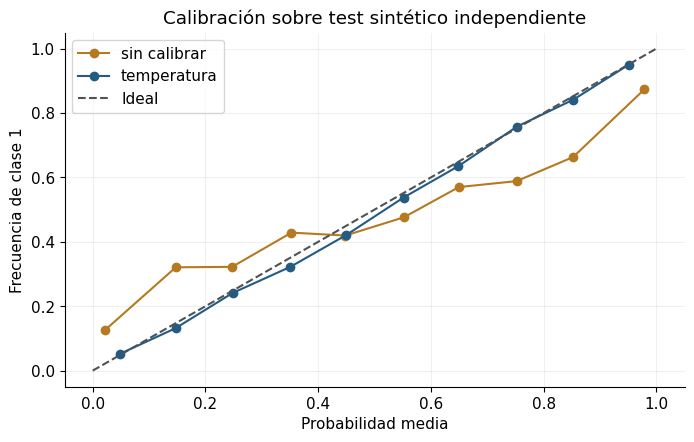

In [5]:
fig,ax=plt.subplots()
for name,p,color in [('sin calibrar',p_raw,GOLD),('temperatura',p_calibrated,BLUE)]:
    bins=np.minimum((p*10).astype(int),9)
    means=[];frequencies=[]
    for j in range(10):
        keep=bins==j
        if keep.any():means.append(p[keep].mean());frequencies.append(y_test[keep].mean())
    ax.plot(means,frequencies,'o-',label=name,color=color)
ax.plot([0,1],[0,1],ls='--',color=GRAY,label='Ideal');ax.set(xlabel='Probabilidad media',ylabel='Frecuencia de clase 1',title='Calibración sobre test sintético independiente');ax.legend();plt.show()

### Selectividad con una cota simultánea

Para cada umbral $t$ se calcula el error entre aceptados. Sobre un grid fijo de $K=50$:

$$U_t=\widehat r_t+\sqrt{\frac{\log(K/\delta)}{2n_t}}.$$

La política elige la mayor cobertura con $U_t\le r_{max}$. La muestra usada para ajustar temperatura se divide nuevamente: el ajuste usa una mitad y la selección del umbral otra. La cota requiere ejemplos IID y reglas fijas antes de observar las etiquetas de selección.

### Ajuste separado de selección

La temperatura anterior era diagnóstico. Se vuelve a ajustar solo con la primera mitad para seleccionar el umbral en la segunda.

In [6]:
half=n_cal//2
opt_sel=minimize_scalar(lambda lt:nll_logits(logit_cal[:half]/np.exp(lt),y_cal[:half]),bounds=(-3,3),method='bounded')
temp_sel=np.exp(opt_sel.x)
p_select=expit(logit_cal[half:]/temp_sel)
conf_select=np.maximum(p_select,1-p_select)
correct_select=((p_select>=.5)==y_cal[half:])
count,threshold,upper=select_threshold(conf_select,correct_select,max_error=.15)
p_test_sel=expit(logit_test/temp_sel)
conf_test=np.maximum(p_test_sel,1-p_test_sel)
correct_test=((p_test_sel>=.5)==y_test)
keep=conf_test>=threshold
print({'umbral':threshold,'cal_aceptados':count,'cota_cal':upper,'cobertura_test':keep.mean(),'error_test_aceptados':float((~correct_test[keep]).mean()) if keep.any() else None})

{'umbral': 0.79, 'cal_aceptados': 1253, 'cota_cal': 0.14907048898363726, 'cobertura_test': np.float64(0.503625), 'error_test_aceptados': 0.0975428145941921}


### Frontera riesgo y cobertura

El test evalúa un umbral congelado; no se usa para seleccionarlo. Error condicional entre aceptados no equivale a error sobre toda la población.

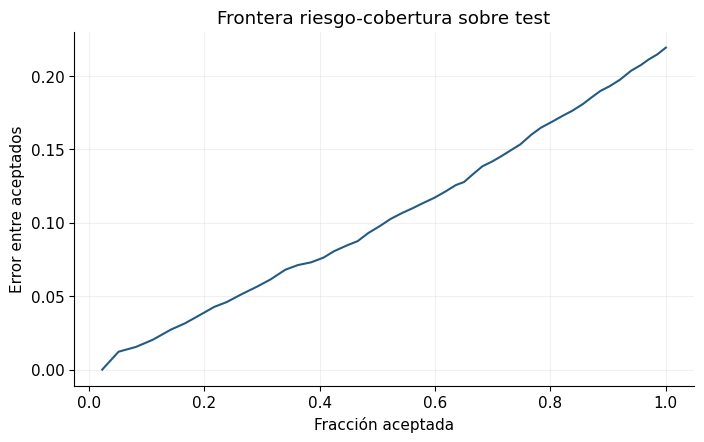

In [7]:
risk_rows=[]
for t in np.linspace(.5,.99,50):
    selected=conf_test>=t
    if selected.any():risk_rows.append((selected.mean(),(~correct_test[selected]).mean()))
risk_rows=np.array(risk_rows)
fig,ax=plt.subplots();ax.plot(risk_rows[:,0],risk_rows[:,1],color=BLUE)
ax.set(xlabel='Fracción aceptada',ylabel='Error entre aceptados',title='Frontera riesgo-cobertura sobre test');plt.show()

### Fallback imperfecto y errores correlacionados

Derivar no garantiza acierto. Comparamos escenarios con 3% de error independiente o errores compartidos.

In [8]:
error_specialist=~correct_test
fallback_independent=rng_depth.random(n_test)<.03
fallback_correlated=(error_specialist & (rng_depth.random(n_test)<.6)) | (rng_depth.random(n_test)<.01)
fallback_rows=[]
for name,error in [('independiente',fallback_independent),('correlacionado',fallback_correlated)]:
    final_error=np.where(keep,error_specialist,error)
    fallback_rows.append({'fallback':name,'error_global':final_error.mean(),'derivacion':(~keep).mean()})
display(pd.DataFrame(fallback_rows))

,fallback,error_global,derivacion
0,independiente,0.062375,0.496375
1,correlacionado,0.157875,0.496375


### Costo esperado por acción

$$C(a|p)=pL(1-q_a)+c_a+(1-p)f_a.$$

Severidad $L=100$, eficacia asumida $q$, costo directo $c$ y fricción legítima $f$ comparten unidades. El ejemplo no estima eficacia causal ni usa importes reales. La acción es una recomendación simulada; no hay rechazo o bloqueo externo.

### Política económica y umbral fijo

Se contrasta el costo real simulado bajo la misma etiqueta y eficacia esperada por clase, no solo número de alertas.

,politica,costo_medio,fraccion_intervenida
0,continuar,49.0125,0.0000
1,umbral .5,19.5905,0.4960
2,costo esperado,14.4581,0.9311


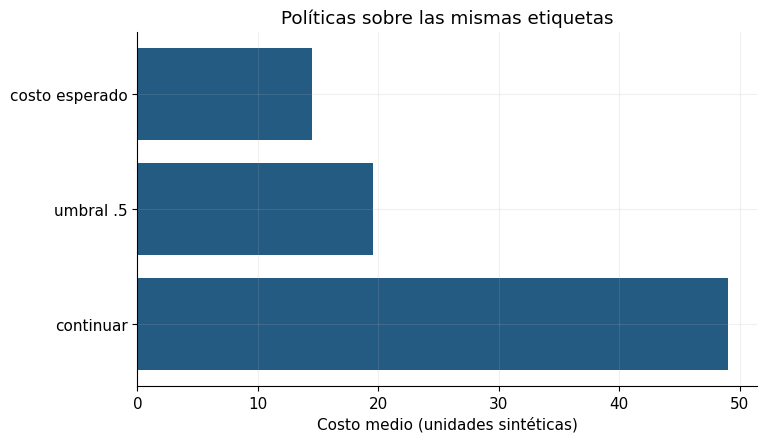

In [9]:
loss=np.full(3,100.);efficacy=np.array([0,.6,.9]);cost=np.array([0,2,8]);friction=np.array([0,1,10])
actions=np.array([choose_action(float(p),loss,efficacy,cost,friction)[0] for p in p_calibrated])
fixed=np.where(p_calibrated>.5,2,0)
policy_rows=[]
for name,a in [('continuar',np.zeros(n_test,dtype=int)),('umbral .5',fixed),('costo esperado',actions)]:
    realized=y_test*loss[a]*(1-efficacy[a])+cost[a]+(1-y_test)*friction[a]
    policy_rows.append({'politica':name,'costo_medio':realized.mean(),'fraccion_intervenida':np.mean(a!=0)})
policy_table=pd.DataFrame(policy_rows);display(policy_table.round(4))
fig,ax=plt.subplots();ax.barh(policy_table.politica,policy_table.costo_medio,color=BLUE);ax.set(xlabel='Costo medio (unidades sintéticas)',title='Políticas sobre las mismas etiquetas');plt.show()

### Cambio condicional después de calibrar

Una inversión parcial de etiquetas conserva el contrato de salida pero deteriora la validez probabilística.

In [10]:
y_shift=y_test.copy();flip=rng_depth.random(n_test)<.2;y_shift[flip]=1-y_shift[flip]
print({'Brier_base':float(np.mean((p_calibrated-y_test)**2)),'Brier_shift':float(np.mean((p_calibrated-y_shift)**2)),
       'riesgo_selectivo_shift':float(np.mean((p_test_sel[keep]>=.5)!=y_shift[keep])) if keep.any() else None})
valid_but_wrong=Decision(('clase0','clase1'),(.01,.99),'fixture-v1')
assert valid_but_wrong.probabilities[1]==.99
print('Contrato válido; ninguna garantía de verdad individual.')

{'Brier_base': 0.15106047841352158, 'Brier_shift': 0.22951214943155446, 'riesgo_selectivo_shift': 0.25788036733680814}
Contrato válido; ninguna garantía de verdad individual.


### Sensibilidad de eficacia

Una política óptima bajo eficacia supuesta puede deteriorarse si la intervención funciona menos de lo esperado.

In [11]:
stress=[]
for multiplier in [0,.25,.5,.75,1.]:
    realized=y_test*loss[actions]*(1-efficacy[actions]*multiplier)+cost[actions]+(1-y_test)*friction[actions]
    stress.append({'factor_eficacia':multiplier,'costo_politica_congelada':realized.mean()})
display(pd.DataFrame(stress).round(3))

,factor_eficacia,costo_politica_congelada
0,0.00,56.372
1,0.25,45.893
2,0.50,35.415
3,0.75,24.937
4,1.00,14.458


## Hallazgos y uso

Las tablas y curvas anteriores muestran por separado calibración, cobertura, errores y costo. La temperatura no cambia AUC; el fallback correlacionado y el cambio condicional exponen fallos que un esquema válido no detecta. Adoptar una API comercial exigiría repetir estas comparaciones con respuestas reales, etiquetas maduras, costos medidos e intervalos de incertidumbre.

### Bootstrap pareado de diferencia de costo

Las políticas se evalúan sobre las mismas etiquetas. IC percentil del generador test IID, condicionado a los modelos y parámetros ya ajustados; no incluye incertidumbre de eficacia.

In [12]:
a=fixed
cost_fixed=y_test*loss[a]*(1-efficacy[a])+cost[a]+(1-y_test)*friction[a]
a=actions
cost_economic=y_test*loss[a]*(1-efficacy[a])+cost[a]+(1-y_test)*friction[a]
difference=cost_economic-cost_fixed
bootstrap=[]
for repeat in range(400):
    sample_index=rng_depth.integers(0,n_test,n_test)
    bootstrap.append(difference[sample_index].mean())
print({'diferencia_economico_menos_fijo':difference.mean(),'IC95_percentil':np.quantile(bootstrap,[.025,.975]).tolist()})

{'diferencia_economico_menos_fijo': np.float64(-5.132375), 'IC95_percentil': [-5.6864156249999995, -4.671103125]}


### Error selectivo por segmento

Un umbral global puede ocultar regiones difíciles. Los grupos están definidos por magnitud de z, sin observar etiquetas de test.

In [13]:
from scipy.stats import binomtest
segments=[]
for label,mask in [('cerca_frontera',np.abs(z_test)<1),('intermedio',(np.abs(z_test)>=1)&(np.abs(z_test)<2)),('extremo',np.abs(z_test)>=2)]:
    selected=keep & mask
    errors=(~correct_test[selected])
    interval=binomtest(int(errors.sum()),len(errors)).proportion_ci(method='wilson') if len(errors) else None
    segments.append({'segmento':label,'n':int(mask.sum()),'aceptados':int(selected.sum()),'cobertura':selected.sum()/mask.sum(),'error':errors.mean() if len(errors) else None,'IC_lo':interval.low if interval else None,'IC_hi':interval.high if interval else None})
display(pd.DataFrame(segments).round(4))

,segmento,n,aceptados,cobertura,error,IC_lo,IC_hi
0,cerca_frontera,3088,0,0.0000,NaN,NaN,NaN
1,intermedio,2428,1545,0.6363,0.1586,0.1412,0.1776
2,extremo,2484,2484,1.0000,0.0596,0.0509,0.0696


### Presupuesto de error y cobertura

La cota se recalcula solo con calibración. El presupuesto más estricto puede hacer imposible automatizar.

In [14]:
selectivity=[]
for budget in [.03,.05,.1,.15,.2]:
    accepted,cut,bound=select_threshold(conf_select,correct_select,max_error=budget)
    selected=conf_test>=cut
    selectivity.append({'presupuesto_error':budget,'umbral':cut,'cota':bound,'cobertura_test':selected.mean(),'error_test':(~correct_test[selected]).mean() if selected.any() else None})
display(pd.DataFrame(selectivity).round(4))

,presupuesto_error,umbral,cota,cobertura_test,error_test
0,0.03,inf,1.0000,0.0000,NaN
1,0.05,inf,1.0000,0.0000,NaN
2,0.10,inf,1.0000,0.0000,NaN
3,0.15,0.79,0.1491,0.5036,0.0975
4,0.20,0.65,0.1950,0.7478,0.1533


### Latencia y costo como escenarios, no benchmarks

Una cascada suma el costo inicial y el fallback en la fracción derivada. El p95 de la mezcla no se calcula promediando p95 individuales.

In [15]:
latency_fast=rng_depth.lognormal(np.log(100),.2,n_test)
latency_fallback=rng_depth.lognormal(np.log(1000),.4,n_test)
latency_cascade=latency_fast+(~keep)*latency_fallback
comparison=[]
for name,latency,unit_cost in [('siempre fallback',latency_fallback,1.),('cascada',latency_cascade,.05+float((~keep).mean()))]:
    comparison.append({'politica':name,'p50_ms_simulado':np.quantile(latency,.5),'p95_ms_simulado':np.quantile(latency,.95),'costo_medio_simulado':unit_cost})
display(pd.DataFrame(comparison).round(3))

,politica,p50_ms_simulado,p95_ms_simulado,costo_medio_simulado
0,siempre fallback,1000.451,1942.117,1.000
1,cascada,165.259,1794.774,0.546


### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Próximos experimentos

Comparar proveedores sobre corpus etiquetado y snapshots iguales; registrar versión y latencia medida. Añadir OCR real aprobado, idioma, distribución temporal y revisores falibles. Diseñar pruebas de integración antes de conectar efectos externos.

Fuentes y contrato de arquitectura: [README principal](../README.md).

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### Regla de Chow y riesgo selectivo

[Chow, IEEE Transactions on Information Theory 1970](https://doi.org/10.1109/TIT.1970.1054406); [El-Yaniv y Wiener, JMLR 2010, definiciones 1–2](https://jmlr.org/papers/v11/el-yaniv10a.html).

Con costo de error $c_e$ y abstención perfecta $c_r$, se acepta si:

$$\max_k p_k\ge1-c_r/c_e.$$

La fórmula resulta de comparar riesgo Bayes de clasificar y abstenerse. Con fallback falible, el costo de derivar es $c_r+c_e\epsilon_f(x)$; cambia el umbral. Cobertura $\phi=E[g(X)]$ y riesgo selectivo $R=E[\ell(f(X),Y)g(X)]/\phi$ se reportan por separado. No se trasladan los teoremas sin ruido de JMLR a nuestras etiquetas Bernoulli ruidosas.

### Oráculo Bayes: abstención perfecta y fallback falible

En este generador conocemos p verdadero. El oráculo sirve como referencia de decisión, no como un proveedor comercial.

In [16]:
p_true=expit(z_test)
error_if_classify=np.minimum(p_true,1-p_true)
reject_cost=.1
rows_chow=[]
for fallback_error in [0.,.05,.15]:
    referral=reject_cost+fallback_error
    accept=error_if_classify<=referral
    oracle_cost=np.where(accept,error_if_classify,referral)
    threshold_cost=np.where(np.maximum(p_true,1-p_true)>=1-referral,error_if_classify,referral)
    assert np.allclose(oracle_cost,threshold_cost)
    rows_chow.append({'fallback_error':fallback_error,'threshold':1-referral,'coverage':float(accept.mean()),'expected_cost':float(oracle_cost.mean())})
display(pd.DataFrame(rows_chow).round(4))

,fallback_error,threshold,coverage,expected_cost
0,0.00,0.90,0.2610,0.0867
1,0.05,0.85,0.3814,0.1205
2,0.15,0.75,0.5790,0.1723


### Confianza reportada frente a incertidumbre real

Se comparan tres señales bajo el mismo costo de abstención perfecta; la confianza inflada puede aceptar demasiado.

ACADEMIC_METRICS:{"Chow_comparison": [{"signal": "oraculo", "coverage": 0.261, "cost": 0.0874, "selective_error": 0.05172413793103448}, {"signal": "sin_calibrar", "coverage": 0.6415, "cost": 0.11685000000000001, "selective_error": 0.12626656274356976}, {"signal": "temperatura", "coverage": 0.268, "cost": 0.08695, "selective_error": 0.051305970149253734}]}


,signal,coverage,cost,selective_error
0,oraculo,0.2610,0.0874,0.0517
1,sin_calibrar,0.6415,0.1168,0.1263
2,temperatura,0.2680,0.0870,0.0513


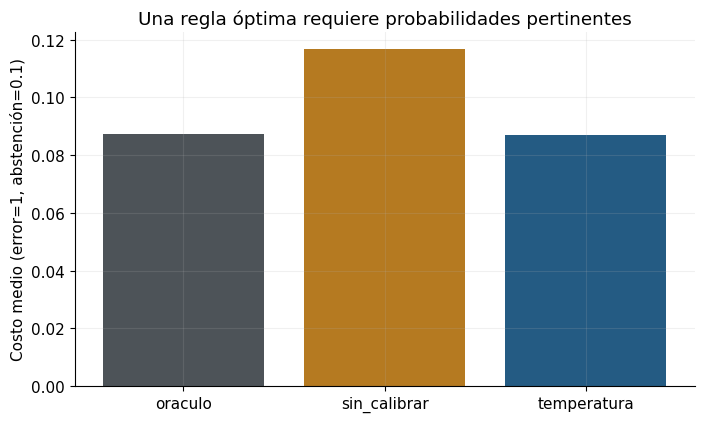

In [17]:
chow_comparison=[]
for name,probability in [('oraculo',p_true),('sin_calibrar',p_raw),('temperatura',p_calibrated)]:
    accept=np.maximum(probability,1-probability)>=.9
    decision=(probability>=.5)
    observed_cost=np.where(accept,decision!=y_test,.1)
    chow_comparison.append({'signal':name,'coverage':float(accept.mean()),'cost':float(observed_cost.mean()),
                            'selective_error':float(np.mean(decision[accept]!=y_test[accept])) if accept.any() else None})
chow_table=pd.DataFrame(chow_comparison);display(chow_table.round(4))
fig,ax=plt.subplots()
ax.bar(chow_table.signal,chow_table.cost,color=[GRAY,GOLD,BLUE])
ax.set(ylabel='Costo medio (error=1, abstención=0.1)',title='Una regla óptima requiere probabilidades pertinentes')
plt.show()
import json
print('ACADEMIC_METRICS:'+json.dumps({'Chow_comparison':chow_comparison}))

### Ideas y cierre pendiente

Estimar error condicional del fallback con etiquetas independientes, comparar garantías exactas binomiales y cota Hoeffding, incorporar capacidad compartida y calibración por grupo. El costo de revisión perfecto es una referencia idealizada; la política real debe representar errores y demora.